
# Wealth Management Client Segmentation & Goal Readiness Analysis

### Financial Analytics | Machine Learning | Client Segmentation | Risk Profiling

---

## 1. Project Overview

Wealth management requires a comprehensive understanding of clients' financial circumstances, investment preferences, risk tolerance and long-term financial objectives.

This project explores how data analytics and unsupervised machine learning can be applied to segment hypothetical financial client profiles into meaningful groups.

Using a synthetically generated financial dataset, the analysis examines relationships between income, savings, investment behaviour, risk preferences and financial goal readiness.

The objective is to demonstrate how analytical methods can identify distinct client profiles, uncover financial patterns and support structured, data-driven insights within a wealth management context.

## 2. Key Objectives

- Develop and analyse financial client profiles.
- Examine relationships between income, savings and investments.
- Apply K-Means clustering to identify distinct client segments.
- Use Principal Component Analysis (PCA) to explore multidimensional financial data.
- Analyse risk preferences and investment behaviour.
- Develop an illustrative financial goal readiness indicator.
- Translate analytical findings into meaningful business insights.

## 3. Tools and Technologies

- Programming Language: Python
- Data Manipulation: Pandas, NumPy
- Data Visualisation: Matplotlib, Seaborn
- Machine Learning: Scikit-learn
- Techniques: K-Means Clustering, PCA and Feature Engineering

## 4. Dataset Description

The analysis uses a synthetically generated dataset representing hypothetical financial client profiles.

All client records, financial values, investment preferences and associated characteristics are simulated for educational and analytical purposes. They do not represent actual individuals, investors, Morgan Stanley clients or confidential financial information.

## 5. Project Scope

The project covers exploratory data analysis, financial feature engineering, client segmentation, risk profile interpretation and illustrative financial goal readiness assessment.

The findings are intended for analytical demonstration and do not constitute financial advice or actual investment recommendations.


In [4]:

# Cell 2: Improved Synthetic Financial Client Dataset

import numpy as np
import pandas as pd

# Reproducibility
np.random.seed(42)

# Number of hypothetical clients
n_clients = 3000

# Generate client demographics
age = np.random.randint(22, 70, n_clients)

# Generate annual income (INR)
annual_income = np.clip(
    np.random.lognormal(
        mean=np.log(1000000),
        sigma=0.65,
        size=n_clients
    ),
    300000,
    5000000
).astype(int)

# Generate monthly expenses as a proportion of income
expense_ratio = np.random.uniform(
    0.35, 0.75, n_clients
)

monthly_expenses = (
    annual_income * expense_ratio / 12
).astype(int)

# Generate savings rates
savings_rate = np.random.uniform(
    0.05, 0.35, n_clients
)

# Estimate accumulated savings over an assumed period
accumulation_years = np.random.uniform(
    1, 10, n_clients
)

total_savings = (
    annual_income *
    savings_rate *
    accumulation_years
).astype(int)

# Generate risk preferences
risk_tolerance = np.random.choice(
    ["Low", "Moderate", "High"],
    n_clients,
    p=[0.35, 0.45, 0.20]
)

# Investment allocation assumptions by risk preference
investment_multipliers = {
    "Low": 0.5,
    "Moderate": 1.0,
    "High": 1.5
}

risk_factor = np.array([
    investment_multipliers[risk]
    for risk in risk_tolerance
])

# Generate investment values
investment_value = (
    total_savings *
    risk_factor *
    np.random.uniform(0.5, 1.5, n_clients)
).astype(int)

# Generate financial goals
investment_goal = np.random.choice(
    [
        "Retirement",
        "Wealth Creation",
        "Education",
        "Home Purchase",
        "Capital Preservation"
    ],
    n_clients
)

# Generate investment horizons
investment_horizon = np.random.randint(
    1, 31, n_clients
)

# Generate employment types
employment_type = np.random.choice(
    [
        "Salaried",
        "Self Employed",
        "Business Owner"
    ],
    n_clients,
    p=[0.65, 0.25, 0.10]
)

# Create final synthetic dataset
client_data = pd.DataFrame({
    "client_id": [
        f"CLIENT_{i:04d}"
        for i in range(1, n_clients + 1)
    ],
    "age": age,
    "annual_income": annual_income,
    "monthly_expenses": monthly_expenses,
    "total_savings": total_savings,
    "investment_value": investment_value,
    "investment_horizon": investment_horizon,
    "risk_tolerance": risk_tolerance,
    "investment_goal": investment_goal,
    "employment_type": employment_type
})

print("Improved synthetic dataset generated!")
print("Total client profiles:", len(client_data))
print("Total attributes:", len(client_data.columns))

display(client_data.head(10))


Improved synthetic dataset generated!
Total client profiles: 3000
Total attributes: 10


,client_id,age,annual_income,monthly_expenses,total_savings,investment_value,investment_horizon,risk_tolerance,investment_goal,employment_type
0,CLIENT_0001,60,906609,51030,837409,1326033,19,High,Capital Preservation,Business Owner
1,CLIENT_0002,50,857229,45431,2132340,1532952,10,Moderate,Capital Preservation,Self Employed
2,CLIENT_0003,36,1256509,47068,1199706,847018,17,Moderate,Wealth Creation,Business Owner
3,CLIENT_0004,64,2999455,178489,877622,1376635,3,High,Retirement,Salaried
4,CLIENT_0005,29,2125196,72923,1942447,1730802,21,Moderate,Wealth Creation,Self Employed
5,CLIENT_0006,42,782709,39181,837971,899137,19,Moderate,Wealth Creation,Salaried
6,CLIENT_0007,60,1422764,42863,361439,270505,19,Low,Home Purchase,Salaried
7,CLIENT_0008,40,2259925,114406,970428,1318829,26,Moderate,Capital Preservation,Salaried
8,CLIENT_0009,44,1303984,50079,487143,247308,22,Moderate,Retirement,Self Employed
9,CLIENT_0010,32,996950,44021,698625,576947,19,High,Home Purchase,Salaried


In [5]:

# Cell 3: Financial Feature Engineering

# Annualise monthly expenses
client_data["annual_expenses"] = (
    client_data["monthly_expenses"] * 12
)

# Estimated annual savings capacity
client_data["annual_savings_capacity"] = (
    client_data["annual_income"] -
    client_data["annual_expenses"]
)

# Savings rate
client_data["savings_rate"] = (
    client_data["annual_savings_capacity"] /
    client_data["annual_income"]
)

# Investment value relative to annual income
client_data["investment_income_ratio"] = (
    client_data["investment_value"] /
    client_data["annual_income"]
)

# Emergency fund coverage in months
client_data["emergency_fund_months"] = (
    client_data["total_savings"] /
    client_data["monthly_expenses"]
)

# Illustrative goal target assumptions
goal_multipliers = {
    "Retirement": 8,
    "Wealth Creation": 5,
    "Education": 2,
    "Home Purchase": 4,
    "Capital Preservation": 3
}

client_data["estimated_goal_target"] = (
    client_data["annual_income"] *
    client_data["investment_goal"].map(goal_multipliers)
)

# Illustrative goal readiness ratio
client_data["goal_readiness_ratio"] = (
    (client_data["total_savings"] +
     client_data["investment_value"]) /
    client_data["estimated_goal_target"]
)

print("Financial feature engineering completed!")

print("\nNew Features Created:")
print([
    "annual_expenses",
    "annual_savings_capacity",
    "savings_rate",
    "investment_income_ratio",
    "emergency_fund_months",
    "estimated_goal_target",
    "goal_readiness_ratio"
])

print("\nUpdated Dataset Shape:", client_data.shape)

display(
    client_data[
        [
            "client_id",
            "annual_income",
            "annual_expenses",
            "savings_rate",
            "investment_income_ratio",
            "emergency_fund_months",
            "goal_readiness_ratio"
        ]
    ].head(10)
)


Financial feature engineering completed!

New Features Created:
['annual_expenses', 'annual_savings_capacity', 'savings_rate', 'investment_income_ratio', 'emergency_fund_months', 'estimated_goal_target', 'goal_readiness_ratio']

Updated Dataset Shape: (3000, 17)


,client_id,annual_income,annual_expenses,savings_rate,investment_income_ratio,emergency_fund_months,goal_readiness_ratio
0,CLIENT_0001,906609,612360,0.324560,1.462629,16.410131,0.795434
1,CLIENT_0002,857229,545172,0.364030,1.788264,46.935793,1.425248
2,CLIENT_0003,1256509,564816,0.550488,0.674104,25.488782,0.325779
3,CLIENT_0004,2999455,2141868,0.285914,0.458962,4.916953,0.093944
4,CLIENT_0005,2125196,875076,0.588238,0.814420,26.636960,0.345686
5,CLIENT_0006,782709,470172,0.399302,1.148750,21.387177,0.443871
6,CLIENT_0007,1422764,514356,0.638481,0.190126,8.432424,0.111042
7,CLIENT_0008,2259925,1372872,0.392514,0.583572,8.482317,0.337660
8,CLIENT_0009,1303984,600948,0.539145,0.189656,9.727491,0.070405
9,CLIENT_0010,996950,528252,0.470132,0.578712,15.870266,0.319869


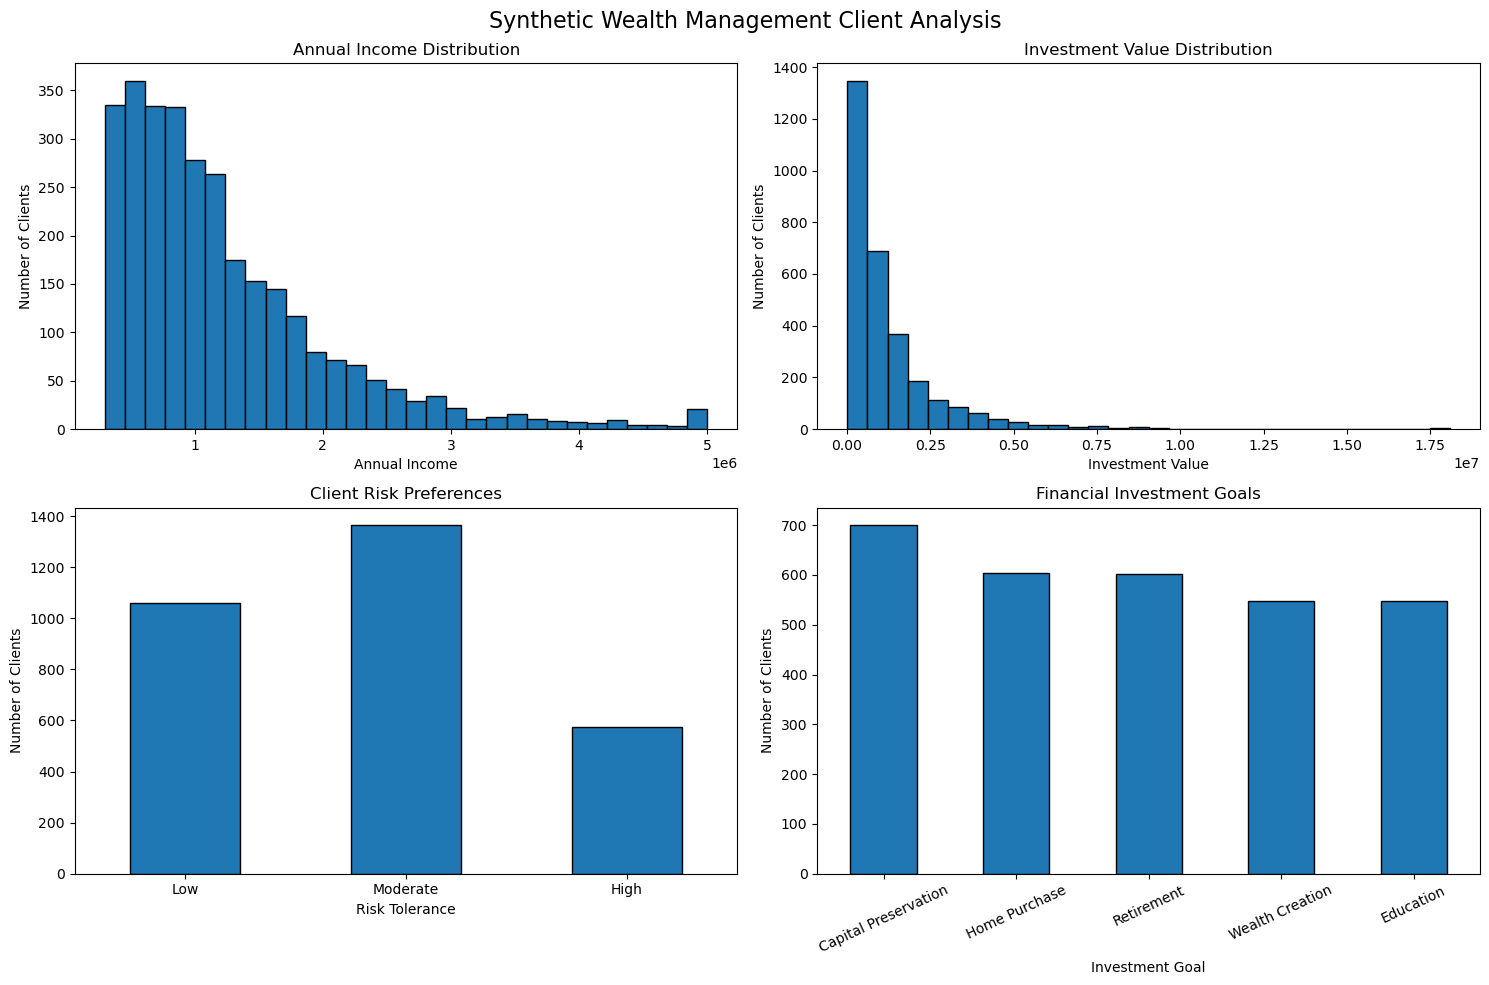

CLIENT FINANCIAL PROFILE SUMMARY


,annual_income,monthly_expenses,total_savings,investment_value,savings_rate,emergency_fund_months,goal_readiness_ratio
count,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00,3000.00
mean,1229898.74,56564.80,1369008.61,1242149.74,0.45,25.20,0.60
std,838141.00,41337.65,1472535.89,1572271.71,0.12,18.51,0.56
min,300000.00,8847.00,27646.00,14141.00,0.25,1.33,0.02
25%,645461.25,28679.75,429013.00,331633.00,0.35,11.14,0.22
50%,1000168.50,44869.50,891174.50,706670.00,0.45,20.30,0.43
75%,1572892.25,72236.75,1798442.75,1519893.75,0.55,34.64,0.79
max,5000000.00,307406.00,15539654.00,18087471.00,0.65,109.03,5.24


In [6]:

# Cell 4: Exploratory Data Analysis

import matplotlib.pyplot as plt

# Create a 2x2 analytical dashboard
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Annual income distribution
axes[0, 0].hist(
    client_data["annual_income"],
    bins=30,
    edgecolor="black"
)
axes[0, 0].set_title("Annual Income Distribution")
axes[0, 0].set_xlabel("Annual Income")
axes[0, 0].set_ylabel("Number of Clients")

# 2. Investment value distribution
axes[0, 1].hist(
    client_data["investment_value"],
    bins=30,
    edgecolor="black"
)
axes[0, 1].set_title("Investment Value Distribution")
axes[0, 1].set_xlabel("Investment Value")
axes[0, 1].set_ylabel("Number of Clients")

# 3. Risk tolerance distribution
client_data["risk_tolerance"].value_counts().reindex(
    ["Low", "Moderate", "High"]
).plot(
    kind="bar",
    ax=axes[1, 0],
    edgecolor="black"
)
axes[1, 0].set_title("Client Risk Preferences")
axes[1, 0].set_xlabel("Risk Tolerance")
axes[1, 0].set_ylabel("Number of Clients")
axes[1, 0].tick_params(axis="x", rotation=0)

# 4. Investment goal distribution
client_data["investment_goal"].value_counts().plot(
    kind="bar",
    ax=axes[1, 1],
    edgecolor="black"
)
axes[1, 1].set_title("Financial Investment Goals")
axes[1, 1].set_xlabel("Investment Goal")
axes[1, 1].set_ylabel("Number of Clients")
axes[1, 1].tick_params(axis="x", rotation=25)

plt.suptitle(
    "Synthetic Wealth Management Client Analysis",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Numerical summary
print("CLIENT FINANCIAL PROFILE SUMMARY")
display(
    client_data[
        [
            "annual_income",
            "monthly_expenses",
            "total_savings",
            "investment_value",
            "savings_rate",
            "emergency_fund_months",
            "goal_readiness_ratio"
        ]
    ].describe().round(2)
)


In [7]:

# Cell 5: Data Cleaning and Validation

# Create a safe working copy
clean_data = client_data.copy()

# Check missing values
missing_values = clean_data.isnull().sum().sum()

# Check duplicate client IDs
duplicate_ids = clean_data["client_id"].duplicated().sum()

# Remove duplicate records
clean_data = clean_data.drop_duplicates(
    subset="client_id"
).copy()

# Check invalid financial values
invalid_income = (clean_data["annual_income"] <= 0).sum()

invalid_expenses = (
    clean_data["monthly_expenses"] <= 0
).sum()

invalid_savings = (
    clean_data["total_savings"] < 0
).sum()

invalid_investments = (
    clean_data["investment_value"] < 0
).sum()

# Remove records with invalid financial values
clean_data = clean_data[
    (clean_data["annual_income"] > 0) &
    (clean_data["monthly_expenses"] > 0) &
    (clean_data["total_savings"] >= 0) &
    (clean_data["investment_value"] >= 0)
].copy()

# Display validation report
print("DATA QUALITY REPORT")
print("------------------------------")

print("Missing values:", missing_values)
print("Duplicate client IDs:", duplicate_ids)
print("Invalid income records:", invalid_income)
print("Invalid expense records:", invalid_expenses)
print("Invalid savings records:", invalid_savings)
print("Invalid investment records:", invalid_investments)

print("\nCLEANED DATASET")
print("------------------------------")
print("Total records:", len(clean_data))
print("Total columns:", len(clean_data.columns))
print("Remaining missing values:",
      clean_data.isnull().sum().sum())

print("\nData cleaning completed successfully!")

display(clean_data.head())


DATA QUALITY REPORT
------------------------------
Missing values: 0
Duplicate client IDs: 0
Invalid income records: 0
Invalid expense records: 0
Invalid savings records: 0
Invalid investment records: 0

CLEANED DATASET
------------------------------
Total records: 3000
Total columns: 17
Remaining missing values: 0

Data cleaning completed successfully!


,client_id,age,annual_income,monthly_expenses,total_savings,investment_value,investment_horizon,risk_tolerance,investment_goal,employment_type,annual_expenses,annual_savings_capacity,savings_rate,investment_income_ratio,emergency_fund_months,estimated_goal_target,goal_readiness_ratio
0,CLIENT_0001,60,906609,51030,837409,1326033,19,High,Capital Preservation,Business Owner,612360,294249,0.324560,1.462629,16.410131,2719827,0.795434
1,CLIENT_0002,50,857229,45431,2132340,1532952,10,Moderate,Capital Preservation,Self Employed,545172,312057,0.364030,1.788264,46.935793,2571687,1.425248
2,CLIENT_0003,36,1256509,47068,1199706,847018,17,Moderate,Wealth Creation,Business Owner,564816,691693,0.550488,0.674104,25.488782,6282545,0.325779
3,CLIENT_0004,64,2999455,178489,877622,1376635,3,High,Retirement,Salaried,2141868,857587,0.285914,0.458962,4.916953,23995640,0.093944
4,CLIENT_0005,29,2125196,72923,1942447,1730802,21,Moderate,Wealth Creation,Self Employed,875076,1250120,0.588238,0.814420,26.636960,10625980,0.345686


In [8]:

# Cell 6: K-Means Client Segmentation

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Select financial features for clustering
clustering_features = [
    "age",
    "annual_income",
    "monthly_expenses",
    "total_savings",
    "investment_value",
    "investment_horizon",
    "savings_rate",
    "investment_income_ratio",
    "emergency_fund_months"
]

# Prepare feature matrix
X = clean_data[clustering_features].copy()

# Standardise financial variables
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

clean_data["client_segment"] = kmeans.fit_predict(
    X_scaled
)

# Evaluate clustering quality
silhouette = silhouette_score(
    X_scaled,
    clean_data["client_segment"]
)

# Display results
print("K-MEANS CLUSTERING COMPLETED")
print("--------------------------------")

print("Number of clusters:", 
      clean_data["client_segment"].nunique())

print("Number of clients:", len(clean_data))

print("Silhouette Score:", round(silhouette, 4))

print("\nCLIENT DISTRIBUTION BY SEGMENT")

print(
    clean_data["client_segment"]
    .value_counts()
    .sort_index()
)

display(
    clean_data[
        ["client_id", "annual_income",
         "total_savings", "investment_value",
         "client_segment"]
    ].head(10)
)


K-MEANS CLUSTERING COMPLETED
--------------------------------
Number of clusters: 4
Number of clients: 3000
Silhouette Score: 0.2071

CLIENT DISTRIBUTION BY SEGMENT
client_segment
0     633
1    1637
2     158
3     572
Name: count, dtype: int64


,client_id,annual_income,total_savings,investment_value,client_segment
0,CLIENT_0001,906609,837409,1326033,1
1,CLIENT_0002,857229,2132340,1532952,0
2,CLIENT_0003,1256509,1199706,847018,1
3,CLIENT_0004,2999455,877622,1376635,3
4,CLIENT_0005,2125196,1942447,1730802,3
5,CLIENT_0006,782709,837971,899137,1
6,CLIENT_0007,1422764,361439,270505,1
7,CLIENT_0008,2259925,970428,1318829,3
8,CLIENT_0009,1303984,487143,247308,1
9,CLIENT_0010,996950,698625,576947,1


PCA ANALYSIS COMPLETED
------------------------------
PC1 Explained Variance: 38.06 %
PC2 Explained Variance: 21.83 %
Combined Explained Variance: 59.88 %


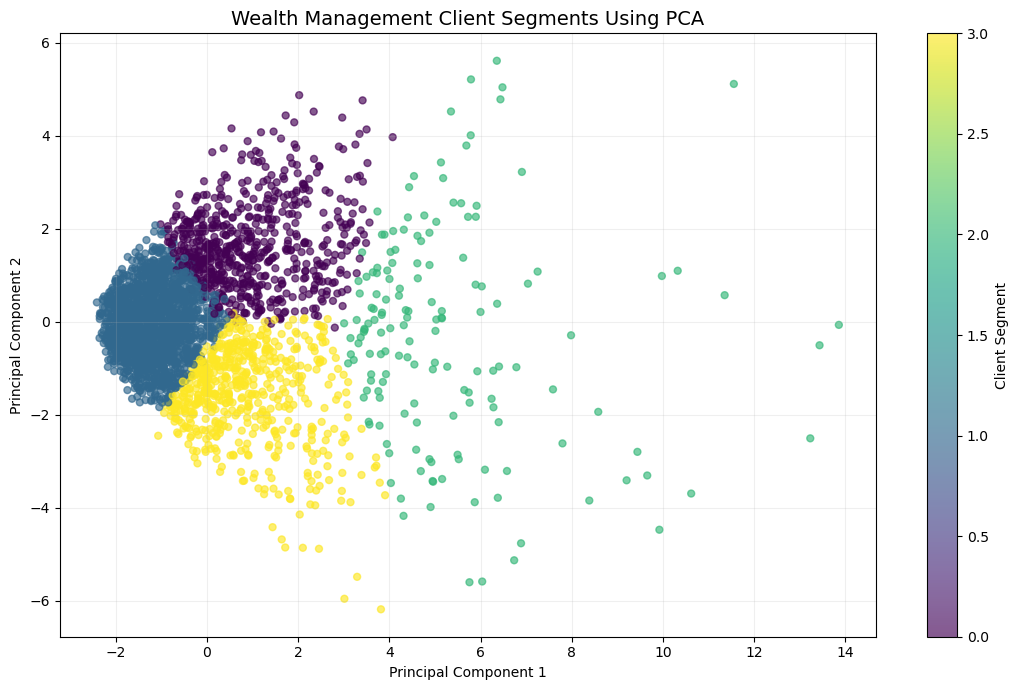

,Principal Component 1,Principal Component 2,Client Segment
0,-0.331007,-0.119642,1
1,0.726425,1.053319,0
2,-0.377357,0.215361,1
3,1.253783,-3.708718,3
4,0.863041,-0.260397,3


PCA ANALYSIS COMPLETED
------------------------------
PC1 Explained Variance: 38.06 %
PC2 Explained Variance: 21.83 %
Combined Explained Variance: 59.88 %


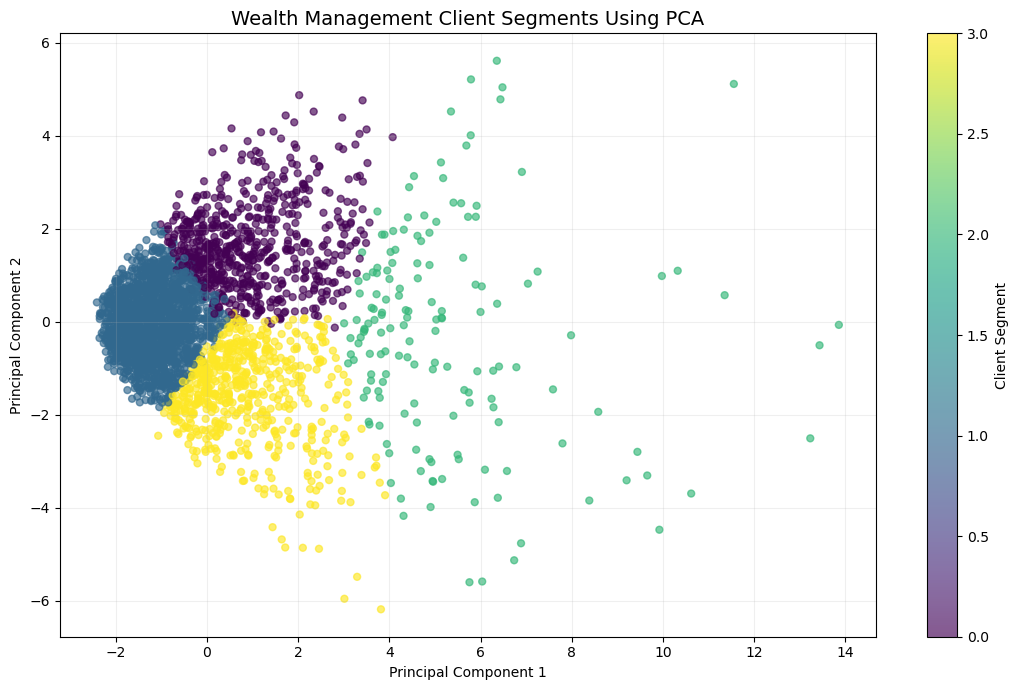

,Principal Component 1,Principal Component 2,Client Segment
0,-0.331007,-0.119642,1
1,0.726425,1.053319,0
2,-0.377357,0.215361,1
3,1.253783,-3.708718,3
4,0.863041,-0.260397,3


In [9]:

# Cell 7: Principal Component Analysis

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce financial features to two principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create PCA results dataframe
pca_data = pd.DataFrame({
    "Principal Component 1": X_pca[:, 0],
    "Principal Component 2": X_pca[:, 1],
    "Client Segment": clean_data["client_segment"].values
})

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_

print("PCA ANALYSIS COMPLETED")
print("------------------------------")

print(
    "PC1 Explained Variance:",
    round(explained_variance[0] * 100, 2), "%"
)

print(
    "PC2 Explained Variance:",
    round(explained_variance[1] * 100, 2), "%"
)

print(
    "Combined Explained Variance:",
    round(explained_variance.sum() * 100, 2), "%"
)

# Visualise client segments
plt.figure(figsize=(11, 7))

scatter = plt.scatter(
    pca_data["Principal Component 1"],
    pca_data["Principal Component 2"],
    c=pca_data["Client Segment"],
    cmap="viridis",
    alpha=0.65,
    s=25
)

plt.title(
    "Wealth Management Client Segments Using PCA",
    fontsize=14
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(
    scatter,
    label="Client Segment"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

display(pca_data.head())

# Cell 7: Principal Component Analysis

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce financial features to two principal components
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

# Create PCA results dataframe
pca_data = pd.DataFrame({
    "Principal Component 1": X_pca[:, 0],
    "Principal Component 2": X_pca[:, 1],
    "Client Segment": clean_data["client_segment"].values
})

# Calculate explained variance
explained_variance = pca.explained_variance_ratio_

print("PCA ANALYSIS COMPLETED")
print("------------------------------")

print(
    "PC1 Explained Variance:",
    round(explained_variance[0] * 100, 2), "%"
)

print(
    "PC2 Explained Variance:",
    round(explained_variance[1] * 100, 2), "%"
)

print(
    "Combined Explained Variance:",
    round(explained_variance.sum() * 100, 2), "%"
)

# Visualise client segments
plt.figure(figsize=(11, 7))

scatter = plt.scatter(
    pca_data["Principal Component 1"],
    pca_data["Principal Component 2"],
    c=pca_data["Client Segment"],
    cmap="viridis",
    alpha=0.65,
    s=25
)

plt.title(
    "Wealth Management Client Segments Using PCA",
    fontsize=14
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.colorbar(
    scatter,
    label="Client Segment"
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

display(pca_data.head())


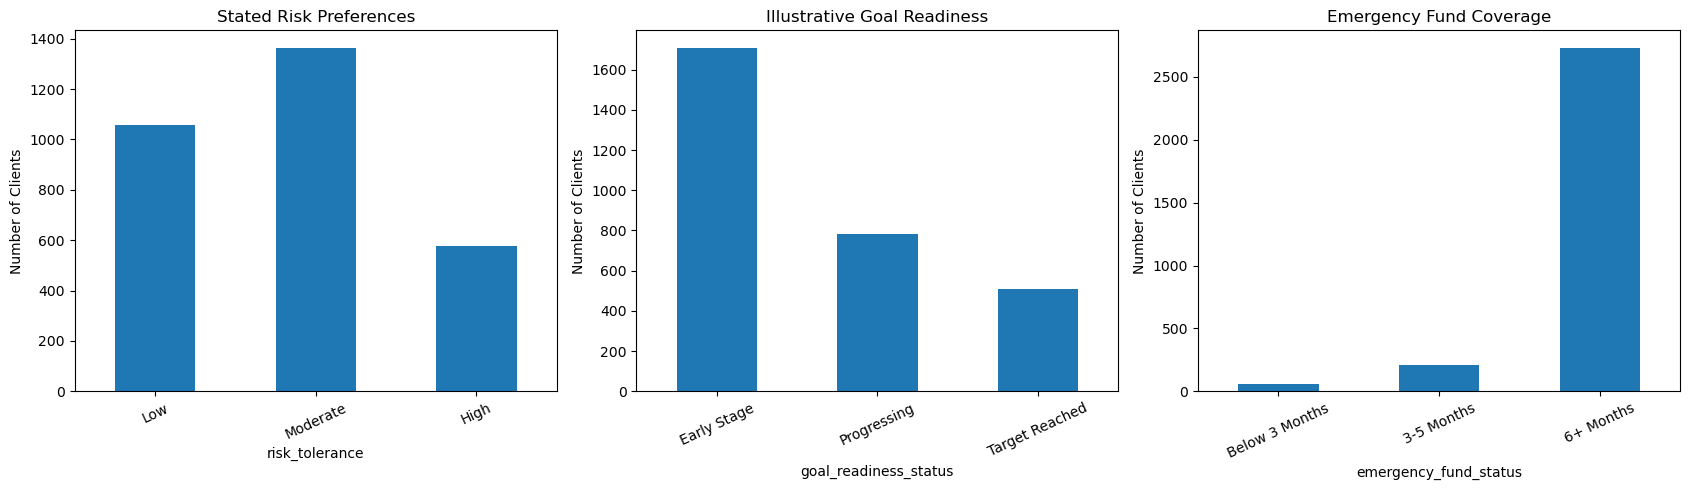

FINANCIAL PROFILE ANALYSIS
--------------------------------

Risk Preference Distribution:
risk_tolerance
Low         1059
Moderate    1365
High         576
Name: count, dtype: int64

Goal Readiness Distribution:
goal_readiness_status
Early Stage       1710
Progressing        781
Target Reached     509
Name: count, dtype: int64

Emergency Fund Distribution:
emergency_fund_status
6+ Months         2733
3-5 Months         208
Below 3 Months      59
Name: count, dtype: int64

Average Goal Readiness Ratio: 0.595


In [10]:

# Cell 8: Financial Risk Profiling and Goal Readiness

# 1. Create illustrative emergency fund categories

clean_data["emergency_fund_status"] = np.select(
    [
        clean_data["emergency_fund_months"] < 3,
        clean_data["emergency_fund_months"] < 6
    ],
    [
        "Below 3 Months",
        "3-5 Months"
    ],
    default="6+ Months"
)

# 2. Classify illustrative goal readiness

clean_data["goal_readiness_status"] = np.select(
    [
        clean_data["goal_readiness_ratio"] < 0.5,
        clean_data["goal_readiness_ratio"] < 1.0
    ],
    [
        "Early Stage",
        "Progressing"
    ],
    default="Target Reached"
)

# 3. Analyse risk preference distribution

risk_distribution = (
    clean_data["risk_tolerance"]
    .value_counts()
    .reindex(["Low", "Moderate", "High"])
)

# 4. Analyse goal readiness distribution

readiness_distribution = (
    clean_data["goal_readiness_status"]
    .value_counts()
)

# 5. Visualise financial profile categories

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

risk_distribution.plot(
    kind="bar",
    ax=axes[0],
    title="Stated Risk Preferences"
)

readiness_distribution.plot(
    kind="bar",
    ax=axes[1],
    title="Illustrative Goal Readiness"
)

clean_data["emergency_fund_status"].value_counts().reindex(
    ["Below 3 Months", "3-5 Months", "6+ Months"]
).plot(
    kind="bar",
    ax=axes[2],
    title="Emergency Fund Coverage"
)

for ax in axes:
    ax.set_ylabel("Number of Clients")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()

# 6. Display summary

print("FINANCIAL PROFILE ANALYSIS")
print("--------------------------------")

print("\nRisk Preference Distribution:")
print(risk_distribution)

print("\nGoal Readiness Distribution:")
print(readiness_distribution)

print("\nEmergency Fund Distribution:")
print(clean_data["emergency_fund_status"].value_counts())

print("\nAverage Goal Readiness Ratio:",
      round(clean_data["goal_readiness_ratio"].mean(), 3))


WEALTH MANAGEMENT CLIENT SEGMENT PROFILES
------------------------------------------


,client_count,median_age,median_income,median_savings,median_investment,average_savings_rate,median_emergency_fund_months,average_goal_readiness,dominant_risk_preference,most_common_goal
client_segment,,,,,,,,,,
0,633,44.0,908566.0,1811701.0,1669770.0,0.49,46.07,1.15,Moderate,Capital Preservation
1,1637,46.0,782501.0,488899.0,378960.0,0.45,14.57,0.37,Moderate,Capital Preservation
2,158,47.0,2787933.0,5256857.5,5373330.5,0.45,44.72,1.28,Moderate,Education
3,572,45.0,2035216.0,1659494.0,1285984.5,0.41,16.58,0.43,Moderate,Capital Preservation


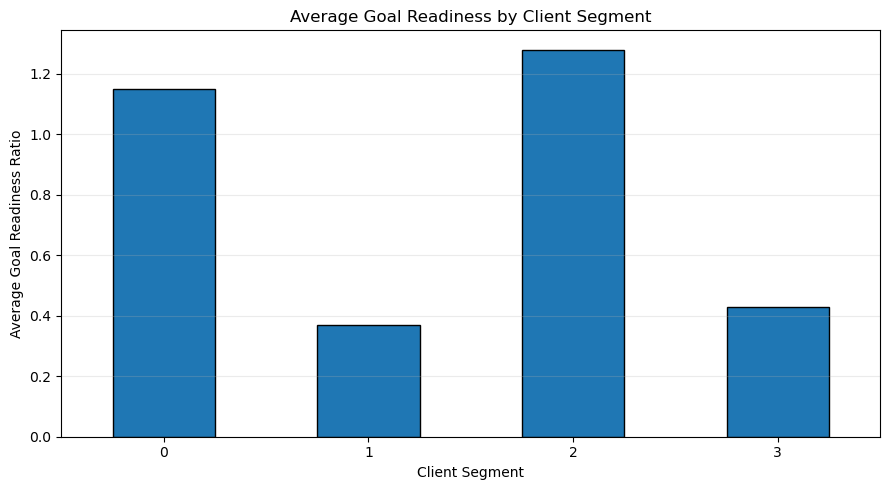


BUSINESS INSIGHTS
------------------------------------------
Largest client segment: 1
Highest average goal readiness segment: 2
Lowest average goal readiness segment: 1

Segment analysis completed successfully!


In [11]:

# Cell 9: Client Segment Profiling and Business Insights

# Create a segment-level financial summary

segment_profile = clean_data.groupby(
    "client_segment"
).agg(
    client_count=("client_id", "count"),
    median_age=("age", "median"),
    median_income=("annual_income", "median"),
    median_savings=("total_savings", "median"),
    median_investment=("investment_value", "median"),
    average_savings_rate=("savings_rate", "mean"),
    median_emergency_fund_months=(
        "emergency_fund_months", "median"
    ),
    average_goal_readiness=(
        "goal_readiness_ratio", "mean"
    )
).round(2)

# Identify dominant risk preference per segment
dominant_risk = clean_data.groupby(
    "client_segment"
)["risk_tolerance"].agg(
    lambda x: x.mode().iloc[0]
)

# Identify most common financial goal per segment
dominant_goal = clean_data.groupby(
    "client_segment"
)["investment_goal"].agg(
    lambda x: x.mode().iloc[0]
)

# Add categorical insights
segment_profile["dominant_risk_preference"] = dominant_risk

segment_profile["most_common_goal"] = dominant_goal

# Display segment profiles
print("WEALTH MANAGEMENT CLIENT SEGMENT PROFILES")
print("------------------------------------------")

display(segment_profile)

# Compare average goal readiness across segments
plt.figure(figsize=(9, 5))

segment_profile["average_goal_readiness"].plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Goal Readiness by Client Segment")
plt.xlabel("Client Segment")
plt.ylabel("Average Goal Readiness Ratio")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# Generate data-driven observations
print("\nBUSINESS INSIGHTS")
print("------------------------------------------")

largest_segment = segment_profile[
    "client_count"
].idxmax()

highest_readiness_segment = segment_profile[
    "average_goal_readiness"
].idxmax()

lowest_readiness_segment = segment_profile[
    "average_goal_readiness"
].idxmin()

print("Largest client segment:", largest_segment)

print(
    "Highest average goal readiness segment:",
    highest_readiness_segment
)

print(
    "Lowest average goal readiness segment:",
    lowest_readiness_segment
)

print("\nSegment analysis completed successfully!")



# 10. Executive Summary & Project Conclusion

## Executive Summary

This project demonstrates the application of Python-based data analytics and unsupervised machine learning to wealth management client segmentation and financial goal readiness analysis.

A dataset containing 3,000 synthetically generated financial client profiles was analysed to explore financial characteristics, investment preferences, savings behaviour and financial objectives.

K-Means clustering was applied to identify distinct client segments based on their financial characteristics. Principal Component Analysis (PCA) was subsequently used to reduce dimensionality and visualise the resulting segments.

Additional financial indicators were developed to examine savings capacity, investment exposure, emergency fund coverage and illustrative goal readiness.

## Key Analytical Components

The analysis incorporated:

- Synthetic financial dataset generation.
- Financial feature engineering.
- Exploratory data analysis and data validation.
- K-Means client segmentation.
- Principal Component Analysis (PCA).
- Financial risk preference analysis.
- Illustrative financial goal readiness assessment.
- Segment-level profiling and business insights.

## Business Relevance

The analytical framework demonstrates how financial data can be transformed into structured client segments and interpretable insights.

Such analytical approaches can support exploratory research into:

- Understanding different financial client profiles.
- Identifying patterns in savings and investment behaviour.
- Comparing financial characteristics across client segments.
- Exploring potential liquidity and financial goal readiness gaps.
- Supporting data-driven wealth management research.

## Project Conclusion

The project demonstrates the use of data analytics, feature engineering and unsupervised machine learning to investigate hypothetical wealth management client profiles.

By combining financial indicators with clustering techniques, the analysis provides a structured approach to understanding similarities and differences across client segments.

The project also highlights the importance of data quality, appropriate feature selection, model evaluation and responsible interpretation when applying machine learning to financial datasets.

## Limitations & Future Scope

- The dataset is simulated and does not represent actual financial client populations.
- The financial goal readiness indicator uses simplified project assumptions.
- Risk preferences are simulated and do not constitute professional risk assessments.
- Future improvements could incorporate validated public financial datasets, more sophisticated financial planning assumptions and additional model evaluation techniques.

## Disclaimer — Data Authenticity & Research Limitations

This project is independently developed for educational, analytical and research purposes.

**All client profiles and financial records used in this project are synthetically generated data.** They do not represent real individuals, actual investors, Morgan Stanley clients, or confidential customer information.

All financial values, client characteristics, investment preferences, financial goals and associated analytical observations are simulated for demonstration purposes.

The results are illustrative and should not be interpreted as actual financial advice, investment recommendations, professional suitability assessments or predictions of real-world financial outcomes.

This project is not affiliated with, endorsed by, or representative of Morgan Stanley or any other financial institution.


In [12]:
import sys

print("Active Python:", sys.executable)
print("Portfolio kernel is responding!")
print("Client records:", len(clean_data))
print("Client segments:", clean_data["client_segment"].nunique())

Active Python: C:\Users\DELL\anaconda3\Anaconda navigator\python.exe
Portfolio kernel is responding!
Client records: 3000
Client segments: 4


In [13]:

# Financial Data Quality Audit

print("FINANCIAL DATA QUALITY AUDIT")
print("=" * 40)

print("\nIncome and Expenses:")
display(
    clean_data[
        ["annual_income", "annual_expenses"]
    ].describe().round(2)
)

print("\nSavings Rate:")
print(clean_data["savings_rate"].describe().round(3))

print("\nEmergency Fund Coverage:")
print(
    clean_data["emergency_fund_months"]
    .describe().round(2)
)

print("\nGoal Readiness:")
print(
    clean_data["goal_readiness_ratio"]
    .describe().round(3)
)

print("\nCluster Distribution:")
print(
    clean_data["client_segment"]
    .value_counts().sort_index()
)

print("\nAudit completed.")


FINANCIAL DATA QUALITY AUDIT

Income and Expenses:


,annual_income,annual_expenses
count,3000.00,3000.00
mean,1229898.74,678777.66
std,838141.00,496051.79
min,300000.00,106164.00
25%,645461.25,344157.00
50%,1000168.50,538434.00
75%,1572892.25,866841.00
max,5000000.00,3688872.00



Savings Rate:
count    3000.000
mean        0.448
std         0.116
min         0.250
25%         0.350
50%         0.447
75%         0.545
max         0.650
Name: savings_rate, dtype: float64

Emergency Fund Coverage:
count    3000.00
mean       25.20
std        18.51
min         1.33
25%        11.14
50%        20.30
75%        34.64
max       109.03
Name: emergency_fund_months, dtype: float64

Goal Readiness:
count    3000.000
mean        0.595
std         0.556
min         0.016
25%         0.215
50%         0.425
75%         0.785
max         5.237
Name: goal_readiness_ratio, dtype: float64

Cluster Distribution:
client_segment
0     633
1    1637
2     158
3     572
Name: count, dtype: int64

Audit completed.
